Samples: 545
Features: 12
Target variable: price (continuous; regression)
Missing values by column:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
Total missing values: 0

Target distribution (price):
count    5.450000e+02
mean     4.766729e+06
std      1.870440e+06
min      1.750000e+06
25%      3.430000e+06
50%      4.340000e+06
75%      5.740000e+06
max      1.330000e+07


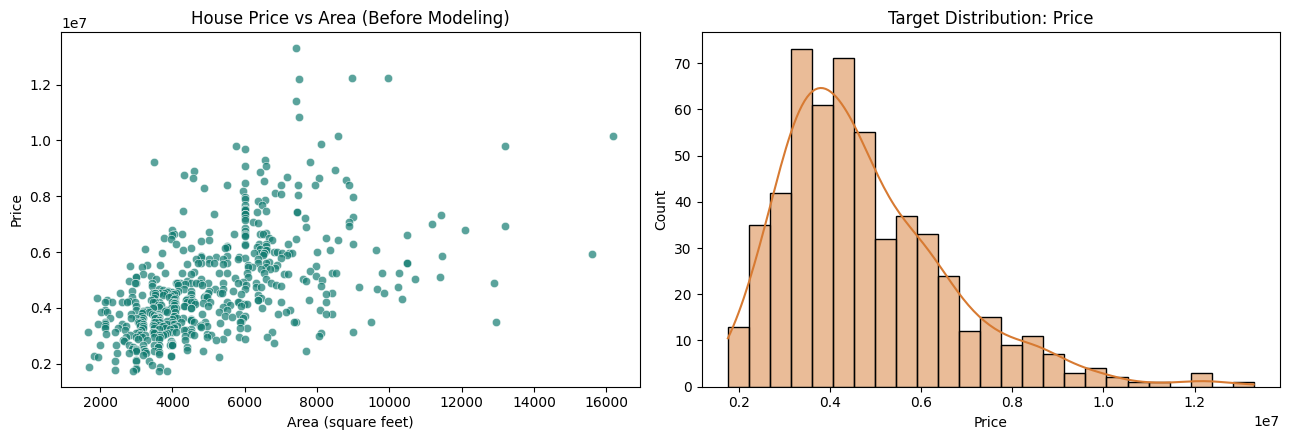

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

DATA_PATH = Path("Housing.csv")
df = pd.read_csv(DATA_PATH)
target = "price"
X = df.drop(columns=target)
y = df[target]

print(f"Samples: {len(df)}")
print(f"Features: {X.shape[1]}")
print(f"Target variable: {target} (continuous; regression)")
print("Missing values by column:")
print(df.isna().sum().to_string())
print(f"Total missing values: {int(df.isna().sum().sum())}")
print("\nTarget distribution (price):")
print(y.describe().to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="area", y=target, alpha=0.7, ax=axes[0], color="#147D72")
axes[0].set_title("House Price vs Area (Before Modeling)")
axes[0].set_xlabel("Area (square feet)")
axes[0].set_ylabel("Price")
sns.histplot(y, bins=25, kde=True, ax=axes[1], color="#D77A32")
axes[1].set_title("Target Distribution: Price")
axes[1].set_xlabel("Price")
plt.tight_layout()
plt.show()

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
models = {
    "Linear Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LinearRegression()),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1
        )),
    ]),
}

predictions = {}
for model_name, model in models.items():
    model.fit(X_train, y_train)
    predictions[model_name] = {
        "train": model.predict(X_train),
        "test": model.predict(X_test),
    }

print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")
print(f"Numeric features: {len(numeric_features)} | Categorical features: {len(categorical_features)}")
print("Both regression pipelines trained successfully.")

Training samples: 436 | Testing samples: 109
Numeric features: 5 | Categorical features: 7
Both regression pipelines trained successfully.


In [3]:
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def regression_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mean_squared_error(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "R2": r2_score(actual, predicted),
        "Pearson correlation": pearsonr(actual, predicted).statistic,
        "Spearman correlation": spearmanr(actual, predicted).statistic,
    }

train_results = pd.DataFrame({
    model_name: regression_metrics(y_train, output["train"])
    for model_name, output in predictions.items()
}).T
test_results = pd.DataFrame({
    model_name: regression_metrics(y_test, output["test"])
    for model_name, output in predictions.items()
}).T

print("Training performance:")
display(train_results.round(4))
print("Testing performance:")
display(test_results.round(4))

Training performance:


,MAE,MSE,RMSE,R2,Pearson correlation,Spearman correlation
Linear Regression,719242.8937,9.683582e+11,984051.9237,0.6859,0.8282,0.8344
Random Forest,393658.7923,3.216007e+11,567098.4767,0.8957,0.9511,0.9478


Testing performance:


,MAE,MSE,RMSE,R2,Pearson correlation,Spearman correlation
Linear Regression,9.700434e+05,1.754319e+12,1.324507e+06,0.6529,0.8210,0.8225
Random Forest,1.041881e+06,1.986161e+12,1.409312e+06,0.6071,0.7897,0.8027


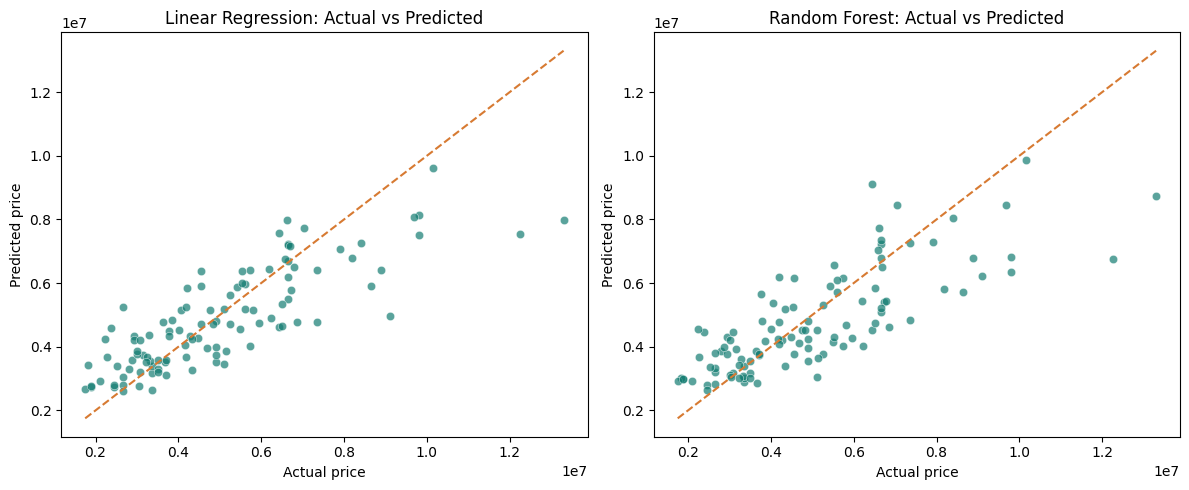

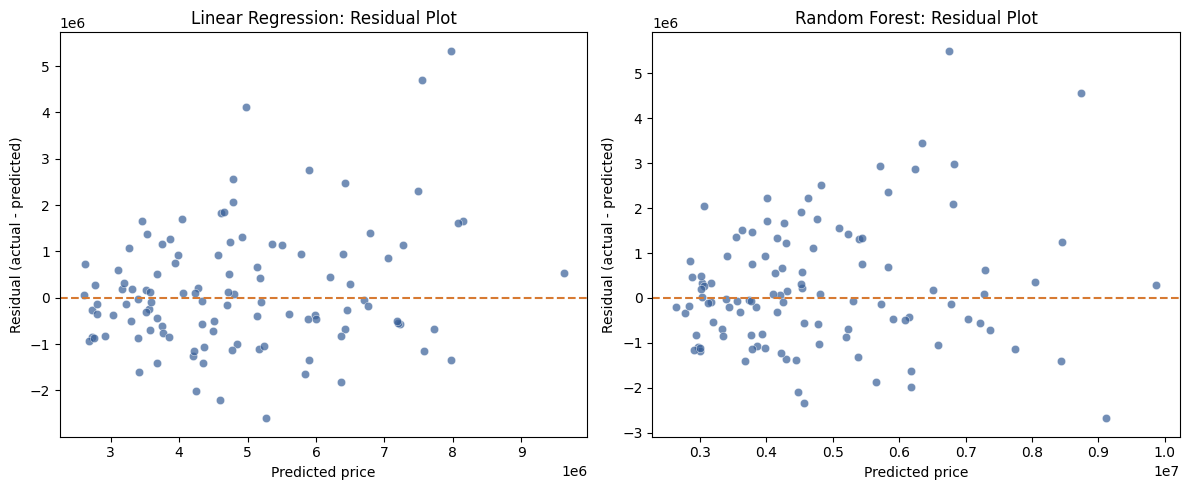

Interpretation:
Linear Regression is selected as the final model because it has the lower test RMSE (1,324,507) and higher test R2 (0.653). The linear model's train-test R2 gap is 0.033; the random forest's is 0.289, indicating a substantially larger generalization gap for the forest. The forest shows overfitting relative to the linear model, while linear regression generalizes better on this held-out split.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for axis, (model_name, output) in zip(axes, predictions.items()):
    actual = y_test
    predicted = output["test"]
    axis.scatter(actual, predicted, alpha=0.7, color="#147D72", edgecolor="white", linewidth=0.4)
    limits = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]
    axis.plot(limits, limits, "--", color="#D77A32", linewidth=1.5)
    axis.set_title(f"{model_name}: Actual vs Predicted")
    axis.set_xlabel("Actual price")
    axis.set_ylabel("Predicted price")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for axis, (model_name, output) in zip(axes, predictions.items()):
    predicted = output["test"]
    residuals = y_test.to_numpy() - predicted
    axis.scatter(predicted, residuals, alpha=0.7, color="#375E97", edgecolor="white", linewidth=0.4)
    axis.axhline(0, linestyle="--", color="#D77A32", linewidth=1.5)
    axis.set_title(f"{model_name}: Residual Plot")
    axis.set_xlabel("Predicted price")
    axis.set_ylabel("Residual (actual - predicted)")
plt.tight_layout()
plt.show()

best_model = test_results["RMSE"].idxmin()
linear_gap = train_results.loc["Linear Regression", "R2"] - test_results.loc["Linear Regression", "R2"]
forest_gap = train_results.loc["Random Forest", "R2"] - test_results.loc["Random Forest", "R2"]
print("Interpretation:")
print(
    f"{best_model} is selected as the final model because it has the lower test RMSE "
    f"({test_results.loc[best_model, 'RMSE']:,.0f}) and higher test R2 "
    f"({test_results.loc[best_model, 'R2']:.3f}). "
    f"The linear model's train-test R2 gap is {linear_gap:.3f}; the random forest's is "
    f"{forest_gap:.3f}, indicating a substantially larger generalization gap for the forest. "
    "The forest shows overfitting relative to the linear model, while linear regression "
    "generalizes better on this held-out split."
)

In [5]:
from IPython.display import Markdown, display

display(Markdown("""
### Task scope

The target, `price`, is continuous, so this dataset follows **Scenario B: Regression**. The target's descriptive statistics above summarize its distribution. A class distribution, confusion matrix, ROC/AUC, and FROC curve are not applicable unless `price` is first converted into labeled categories, which would change the task.
"""))


### Task scope

The target, `price`, is continuous, so this dataset follows **Scenario B: Regression**. The target's descriptive statistics above summarize its distribution. A class distribution, confusion matrix, ROC/AUC, and FROC curve are not applicable unless `price` is first converted into labeled categories, which would change the task.
